In [4]:
import sys
from pathlib import Path
import torch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import pandas as pd
import numpy as np
from safetensors.torch import load_file

# Configuration
RESULTS_DIR = Path("../results/model_comparison/similarities")
# Base path for ID measures (results directory)
ID_RESULTS_BASE = Path("../results")
PLOTS_DIR = Path("../plots/models_similarity")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Identifiers must match what was used in the script (split by /)
# These are used for similarity filenames
MODEL_A_ID = "llava-1.5-7b-hf"  # Finetuned (Rows)
MODEL_B_ID = "llava-v1.5-7b-pretrained-liuhaotian" # Pretrained (Columns)

# Mapping from similarity IDs to folder names for ID data loading
ID_MODEL_DIRS = {
    # Key should match MODEL_A_ID / B_ID or just map clearly
    "Finetuned": "llava-1.5-7b-hf",
    "Pretrained": "llava-v1.5-mlp2x-336px-pretrain-vicuna-7b-v1.5"
}

# Explicitly map the IDs to "Finetuned" and "Pretrained" roles
MODEL_ROLES = {
    MODEL_A_ID: "Finetuned",
    MODEL_B_ID: "Pretrained"
}

DATASETS = {
    "cocoqa_txt": "Text QA",
    "cocoqa_img": "Image QA"
}

MEASURES = {
    "neighborhood_overlap": "Neighborhood Overlap",
    "linear_cka": "Linear CKA",
    "distance_correlation": "Distance Correlation",
    "id_correlation": "ID Correlation",
    "information_imbalance": "II Complement (Finetuned->Pretrained)",
    "information_imbalance_reversed": "II Complement (Pretrained->Finetuned)",
    "information_imbalance_mean": "II Complement (Mean)"
}

In [5]:
def load_data(dataset_key, measure_key):
    # Filename format: {dataset}_{model_a}_vs_{model_b}_{measure}.safetensors
    filename = f"{dataset_key}_{MODEL_A_ID}_vs_{MODEL_B_ID}_{measure_key}.safetensors"
    path = RESULTS_DIR / filename
    try:
        data = load_file(str(path))
        tensor = data[measure_key]
        val = tensor.cpu().numpy()
        # Invert Information Imbalance so higher is better (1 - II)
        if "information_imbalance" in measure_key:
            val = 1 - val
        return val
    except Exception as e:
        print(f"Error loading {filename}: {e}")
        return None

def load_id_data(dataset_key, role_key):
    """
    Load Intrinsic Dimension data.
    dataset_key: 'cocoqa_img' or 'cocoqa_txt'
    role_key: 'Pretrained' or 'Finetuned'
    """
    model_dir = ID_MODEL_DIRS[role_key]
    # Path construction: results/{dataset}/models_data_measures/{model_dir}/id_...
    path = ID_RESULTS_BASE / dataset_key / "models_data_measures" / model_dir / "id_16_100_output_layer_last.safetensors"
    
    try:
        data = load_file(str(path))
        tensor = data["layers_intrinsic_dimension"]
        return tensor.cpu().numpy()
    except Exception as e:
        print(f"Error loading ID data from {path}: {e}")
        return None

def plot_model_comparison(measure_key, measure_title):
    # Load similarity data for both datasets
    sim_txt = load_data("cocoqa_txt", measure_key)
    sim_img = load_data("cocoqa_img", measure_key)
    
    # Load ID data for both models for both datasets
    # Structure: 
    # For Text QA dataset: we need ID for both Pretrained and Finetuned on Text data
    id_txt_pm = load_id_data("cocoqa_txt", "Pretrained")
    id_txt_fm = load_id_data("cocoqa_txt", "Finetuned")
    
    # For Image QA dataset: we need ID for both models on Image data
    id_img_pm = load_id_data("cocoqa_img", "Pretrained")
    id_img_fm = load_id_data("cocoqa_img", "Finetuned")
    
    # Check for missing data (basic check, could be more granular)
    if any(x is None for x in [sim_txt, sim_img, id_txt_pm, id_txt_fm, id_img_pm, id_img_fm]):
        print(f"Skipping plot for {measure_title} due to missing data.")
        return

    # Calculate differences (Text - Image)
    sim_diff = sim_txt - sim_img
    
    # X frontal axis: Difference for Pretrained model (Text - Image)
    id_pm_diff = id_txt_pm - id_img_pm
    
    # Y frontal axis: Difference for Finetuned model (Text - Image)
    id_fm_diff = id_txt_fm - id_img_fm
    
    # Determine scale for difference heatmap (centered at 0)
    max_diff = max(abs(np.nanmin(sim_diff)), abs(np.nanmax(sim_diff)))

    # Setup figure
    # We now have 3 columns: Text QA, Image QA, Difference
    fig = plt.figure(figsize=(26, 10))
    
    # Outer Grid: Top Area (Plots), Bottom Area (Colorbar)
    # 3 Columns
    gs = gridspec.GridSpec(2, 3, height_ratios=[1, 0.08], width_ratios=[1, 1, 1], hspace=0.25, wspace=0.2)
    
    # List of datasets to plot
    # Each entry: (Dataset Title, Sim Matrix, ID_Pretrained (X-axis), ID_Finetuned (Y-axis), Colormap, Vmin, Vmax)
    datasets_list = [
        ("Text QA", sim_txt, id_txt_pm, id_txt_fm, "viridis", 0, 1),
        ("Image QA", sim_img, id_img_pm, id_img_fm, "viridis", 0, 1),
        ("Difference (TXT - MM)", sim_diff, id_pm_diff, id_fm_diff, "coolwarm", -max_diff, max_diff)
    ]

    main_heatmaps = [] # To store mappables for colorbars
    
    for idx, (ds_title, sim_data, id_pm, id_fm, cmap, vmin, vmax) in enumerate(datasets_list):
        
        # Inner Grid for each dataset: 2x2
        # R0: [Top Plot (Pretrained ID), Empty]
        # R1: [Heatmap, Right Plot (Finetuned ID)]
        gs_inner = gridspec.GridSpecFromSubplotSpec(2, 2, subplot_spec=gs[0, idx],
                                                    width_ratios=[6, 1], height_ratios=[1, 6],
                                                    wspace=0.03, hspace=0.03)
        
        ax_top = fig.add_subplot(gs_inner[0, 0])
        ax_main = fig.add_subplot(gs_inner[1, 0])
        ax_right = fig.add_subplot(gs_inner[1, 1])
        
        # Share axes
        ax_top.sharex(ax_main)
        ax_right.sharey(ax_main)

        # 1. Main Heatmap
        # Rows = Finetuned, Cols = Pretrained
        hm = sns.heatmap(
            sim_data,
            ax=ax_main,
            cmap=cmap,
            vmin=vmin, vmax=vmax,
            center=0 if idx == 2 else None, # Center for difference plot
            square=False,
            cbar=False
        )
        if idx == 0 or idx == 2:
            main_heatmaps.append(hm.collections[0])
        
        # Centers for 1D plots
        x_centers = np.arange(len(id_pm)) + 0.5
        y_centers = np.arange(len(id_fm)) + 0.5
        
        # 2. Top Plot (Pretrained ID - X axis)
        # Use Blue-ish color
        ax_top.plot(x_centers, id_pm, color='#377eb8', lw=2)
        # fill_between with 0 baseline handles both positive and negative (for diff)
        ax_top.fill_between(x_centers, id_pm, 0, color='#377eb8', alpha=0.3)
        
        # Formatting Top Plot
        sns.despine(ax=ax_top, bottom=True, left=False)
        ax_top.tick_params(bottom=False, labelbottom=False)
        ax_top.tick_params(axis='y', labelsize=8)
        if idx == 0 or idx == 1:
            ax_top.set_ylabel("ID", fontsize=9, rotation=0, labelpad=15)
        else:
            ax_top.set_ylabel("Δ ID", fontsize=9, rotation=0, labelpad=15)
        
        # 3. Right Plot (Finetuned ID - Y axis)
        # Use Red-ish color
        ax_right.plot(id_fm, y_centers, color='#e41a1c', lw=2)
        # fill_betweenx with 0 baseline
        ax_right.fill_betweenx(y_centers, id_fm, 0, color='#e41a1c', alpha=0.3)
        
        # Formatting Right Plot
        sns.despine(ax=ax_right, left=True, bottom=False)
        ax_right.tick_params(left=False, labelleft=False)
        ax_right.tick_params(axis='x', labelsize=8)
        if idx == 0 or idx == 1:
            ax_right.set_xlabel("ID", fontsize=9)
        else:
            ax_right.set_xlabel("Δ ID", fontsize=9)
        
        # Formatting Main Axis
        # Add Dataset Title on TOP AXIS instead of main axis to clear overlap
        ax_top.set_title(f"{ds_title}", fontsize=18, pad=13, fontweight='medium')
        ax_main.set_xlabel("Pretrained Model Layers", fontsize=13, labelpad=8)
        # Only set ylabel for the first plot to avoid clutter, or maybe for the diff plot too if needed?
        # Let's keep Y label on leftmost plot only for cleanliness, but Diff plot is far right.
        if idx == 0:
            ax_main.set_ylabel("Finetuned Model Layers", fontsize=13, labelpad=8)
        
        ax_main.invert_yaxis() # 0 at bottom
        
        # Ticks
        num_layers = sim_data.shape[0]
        ticks = range(0, num_layers, 5)
        ax_main.set_xticks([t + 0.5 for t in ticks])
        ax_main.set_xticklabels(ticks, fontsize=11)
        ax_main.set_yticks([t + 0.5 for t in ticks])
        ax_main.set_yticklabels(ticks, fontsize=11)
        

    # Colorbars
    
    # 1. Shared Colorbar for Text QA and Image QA (Columns 0 and 1)
    cax_shared = fig.add_subplot(gs[1, 0:2])
    plt.colorbar(main_heatmaps[0], cax=cax_shared, orientation='horizontal', label=f"{measure_title} (0 to 1)")

    # 2. Separate Colorbar for Difference (Column 2)
    cax_diff = fig.add_subplot(gs[1, 2])
    plt.colorbar(main_heatmaps[1], cax=cax_diff, orientation='horizontal', label=f"Difference ({measure_title})")

    plt.suptitle(f"{measure_title}: Pretrained vs Finetuned Layer Similarity & differences",#\n(with Intrinsic Dimension Marginals)", 
                 fontsize=22, fontweight='bold', y=0.98)
    
    # Save
    save_path = PLOTS_DIR / f"models_similarity_{measure_key}_with_id.png"
    plt.savefig(save_path, dpi=300, bbox_inches="tight", facecolor='white')
    print(f"Saved plot to {save_path}")
    plt.show()

Saved plot to ../plots/models_similarity/models_similarity_neighborhood_overlap_with_id.png


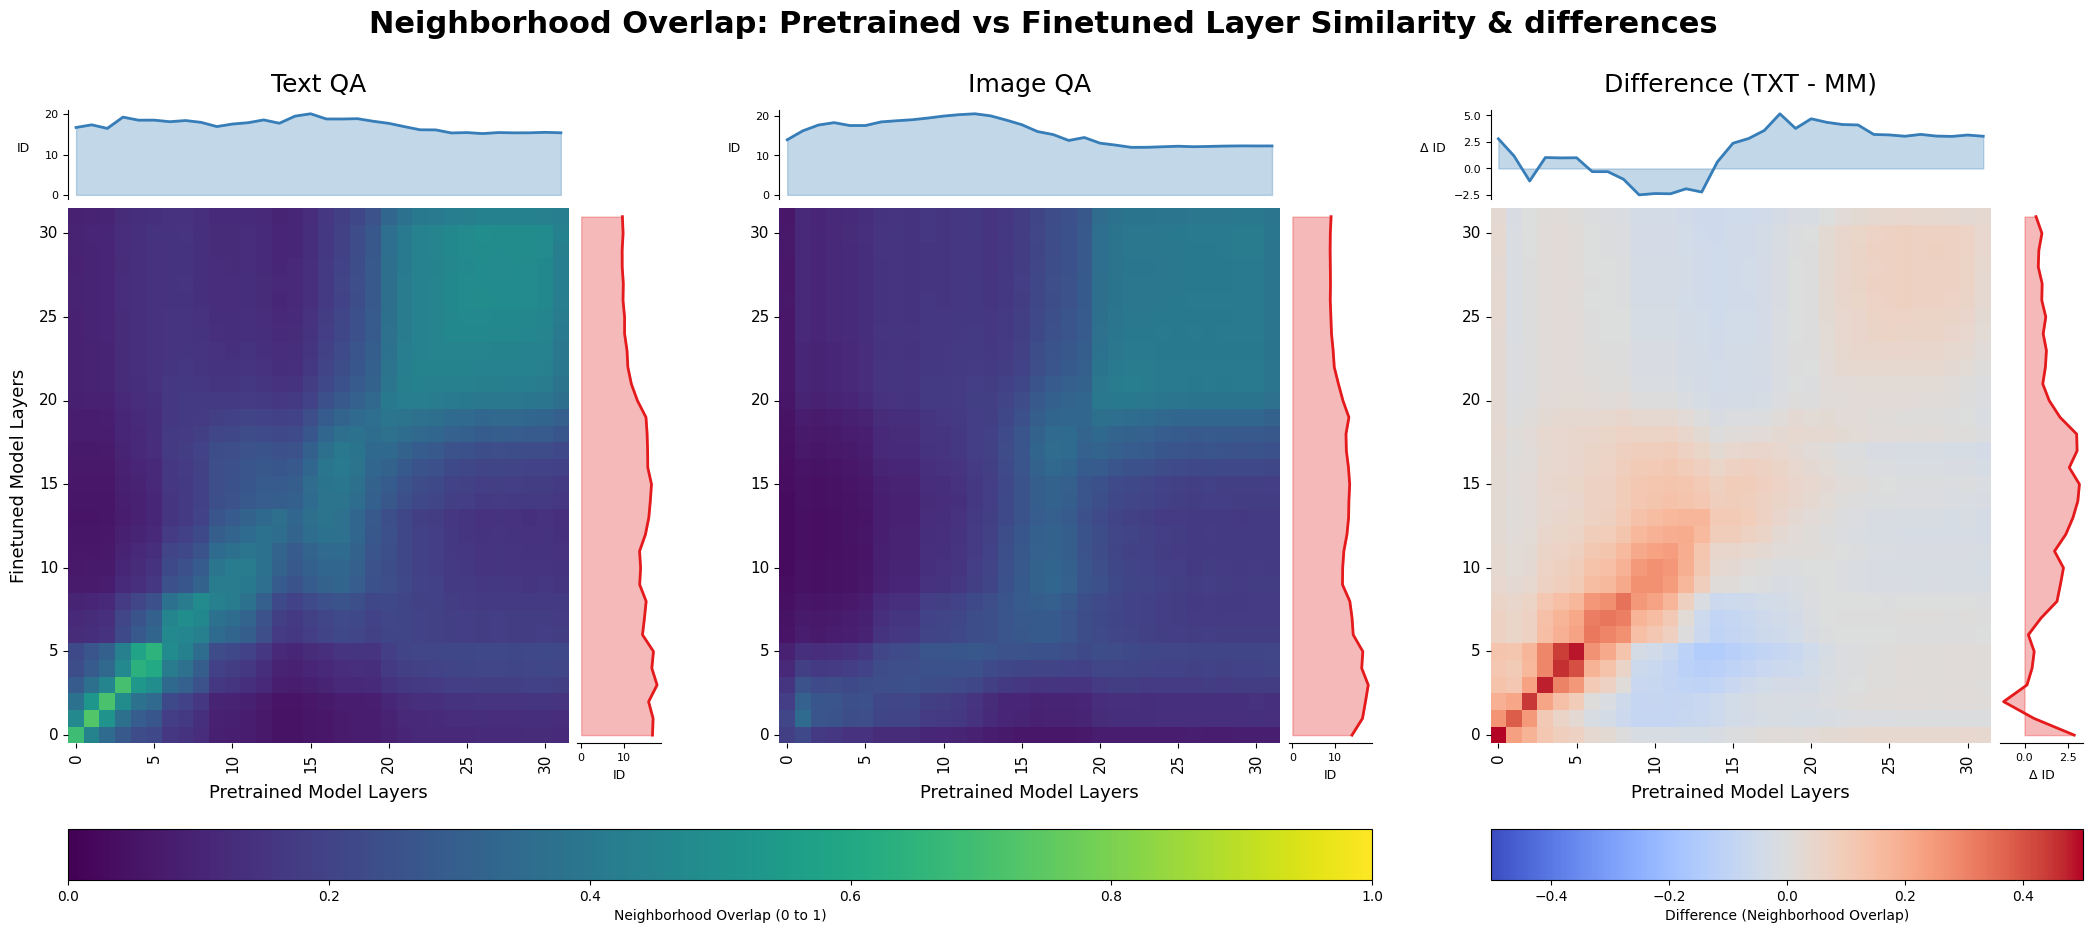

Saved plot to ../plots/models_similarity/models_similarity_linear_cka_with_id.png


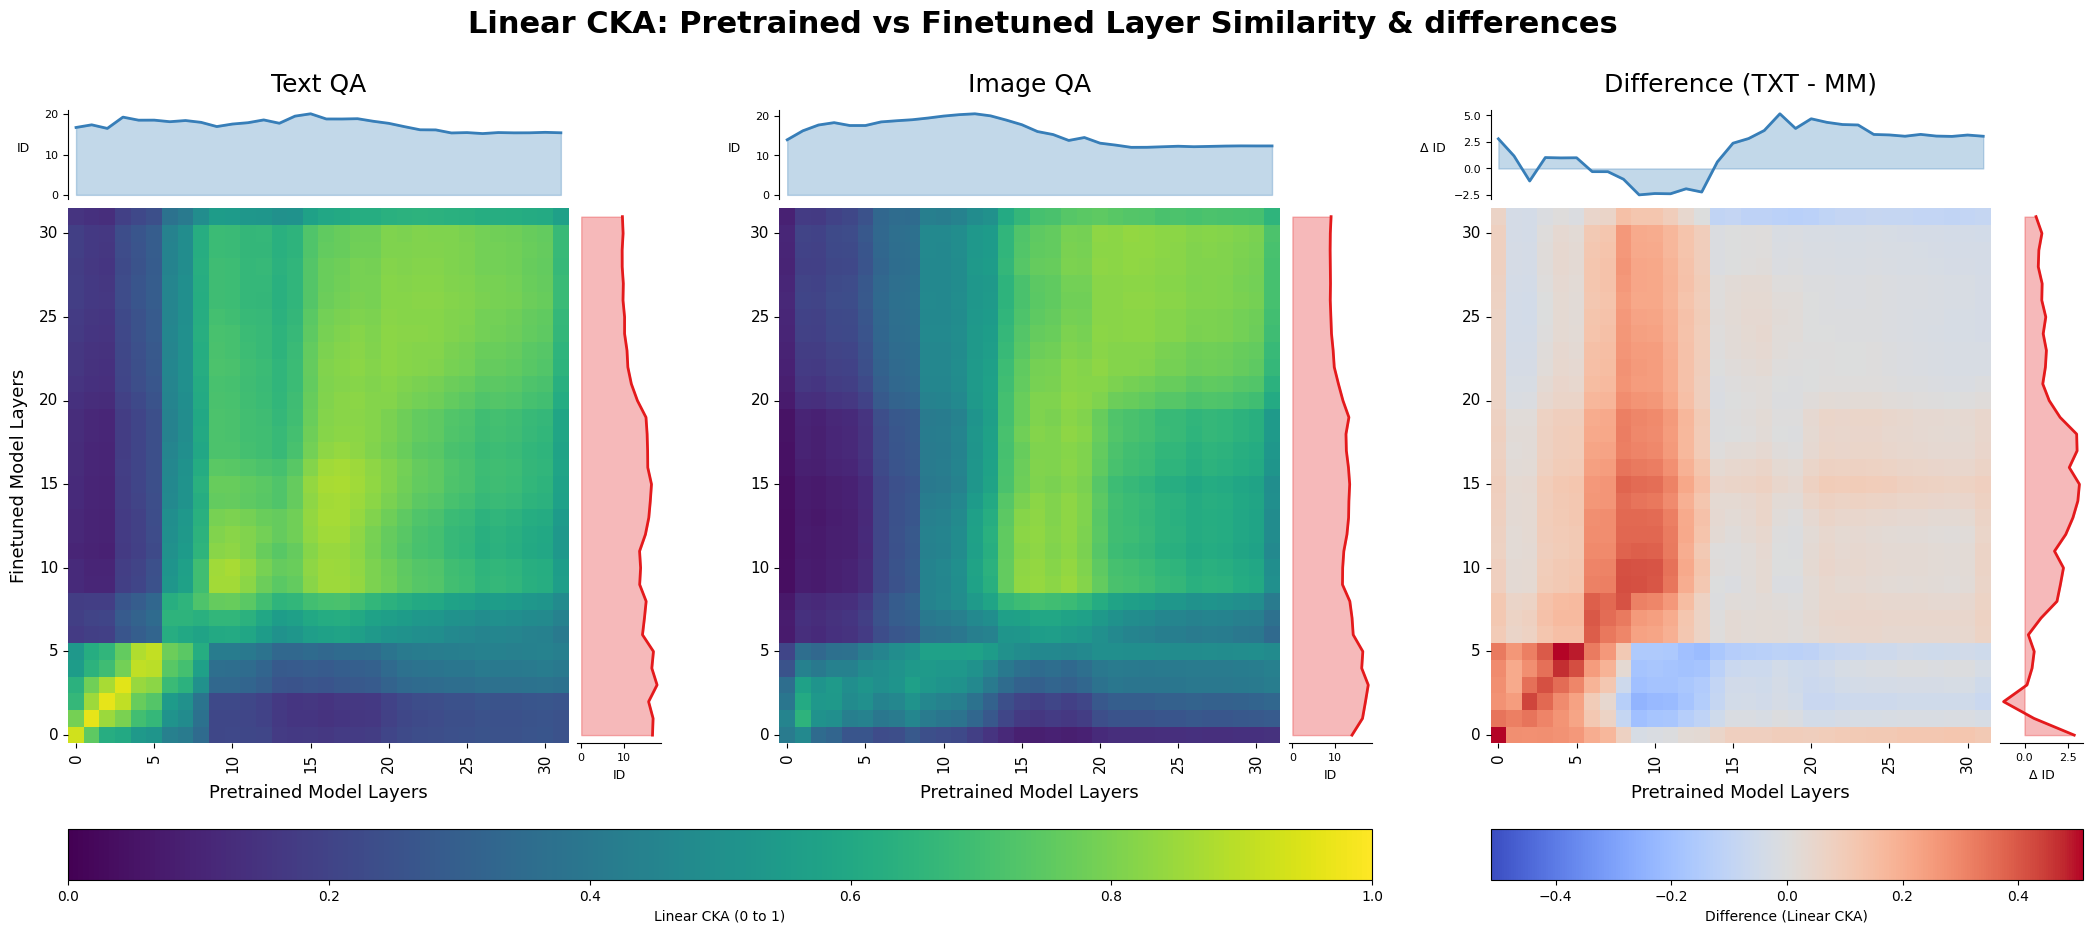

Saved plot to ../plots/models_similarity/models_similarity_distance_correlation_with_id.png


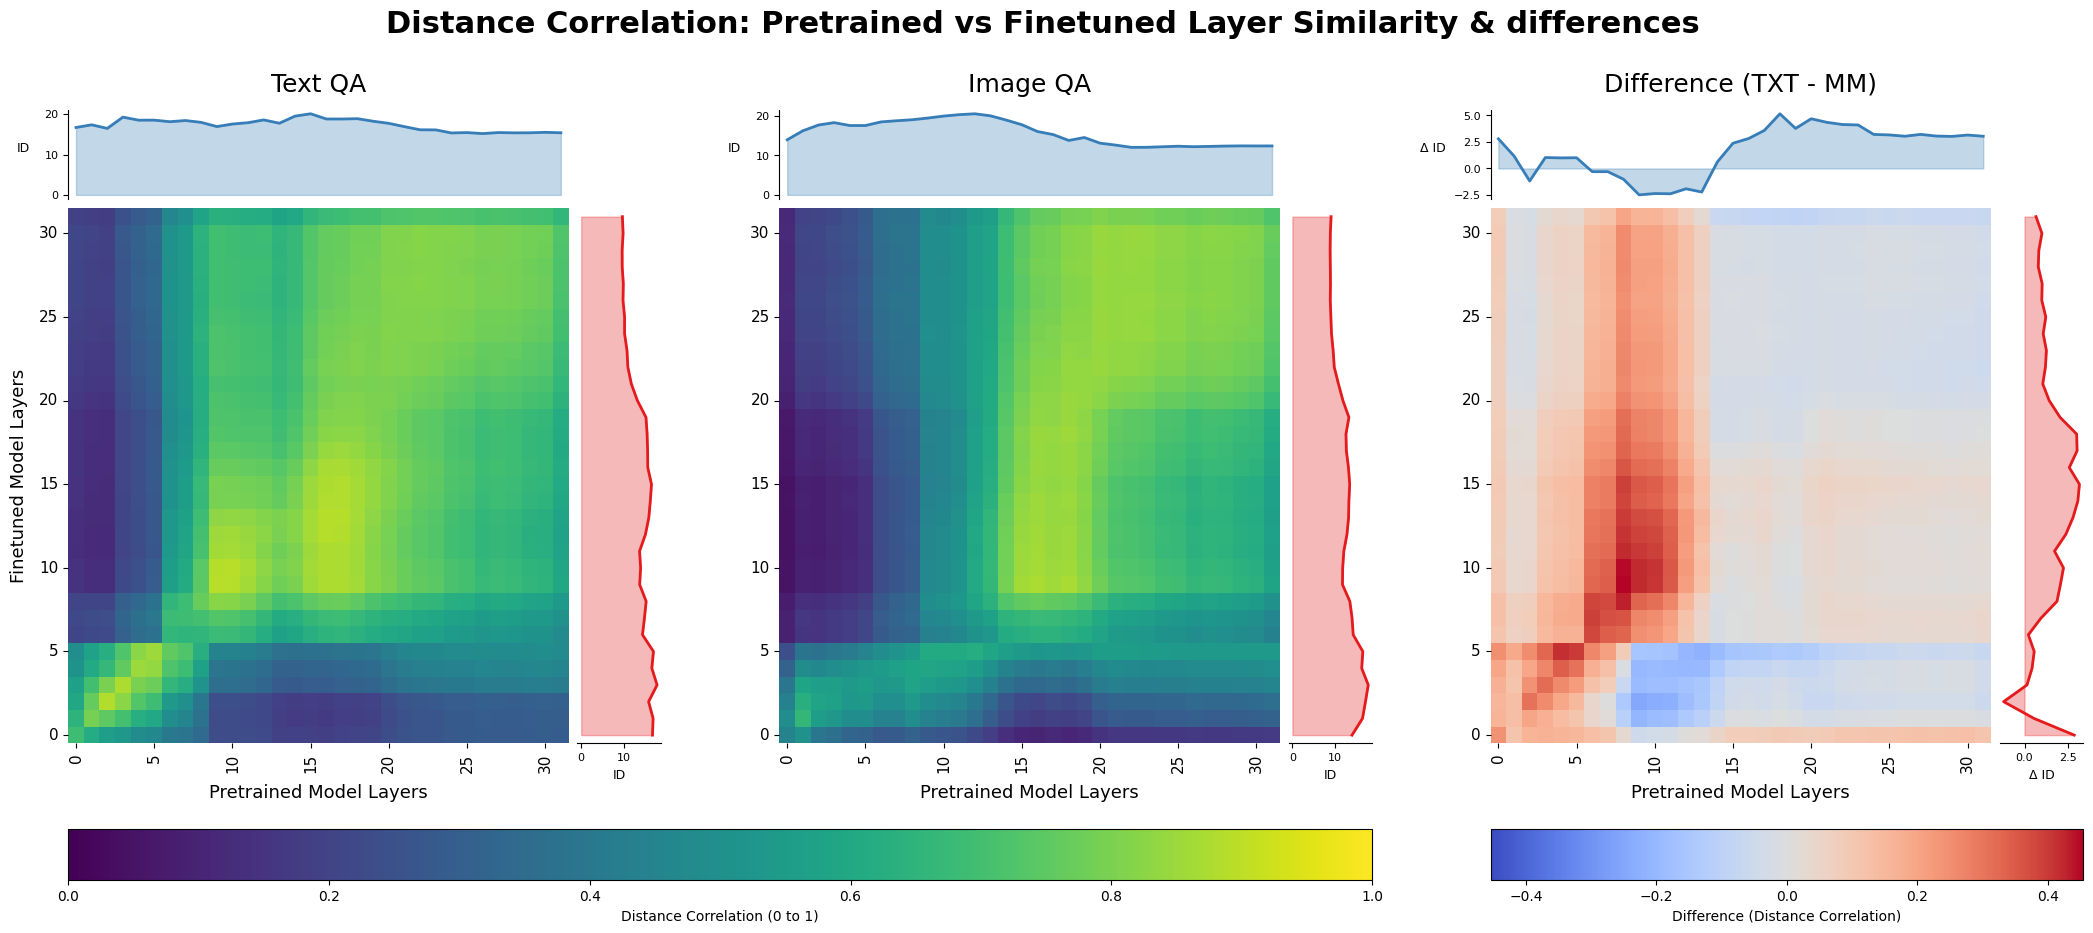

Saved plot to ../plots/models_similarity/models_similarity_id_correlation_with_id.png


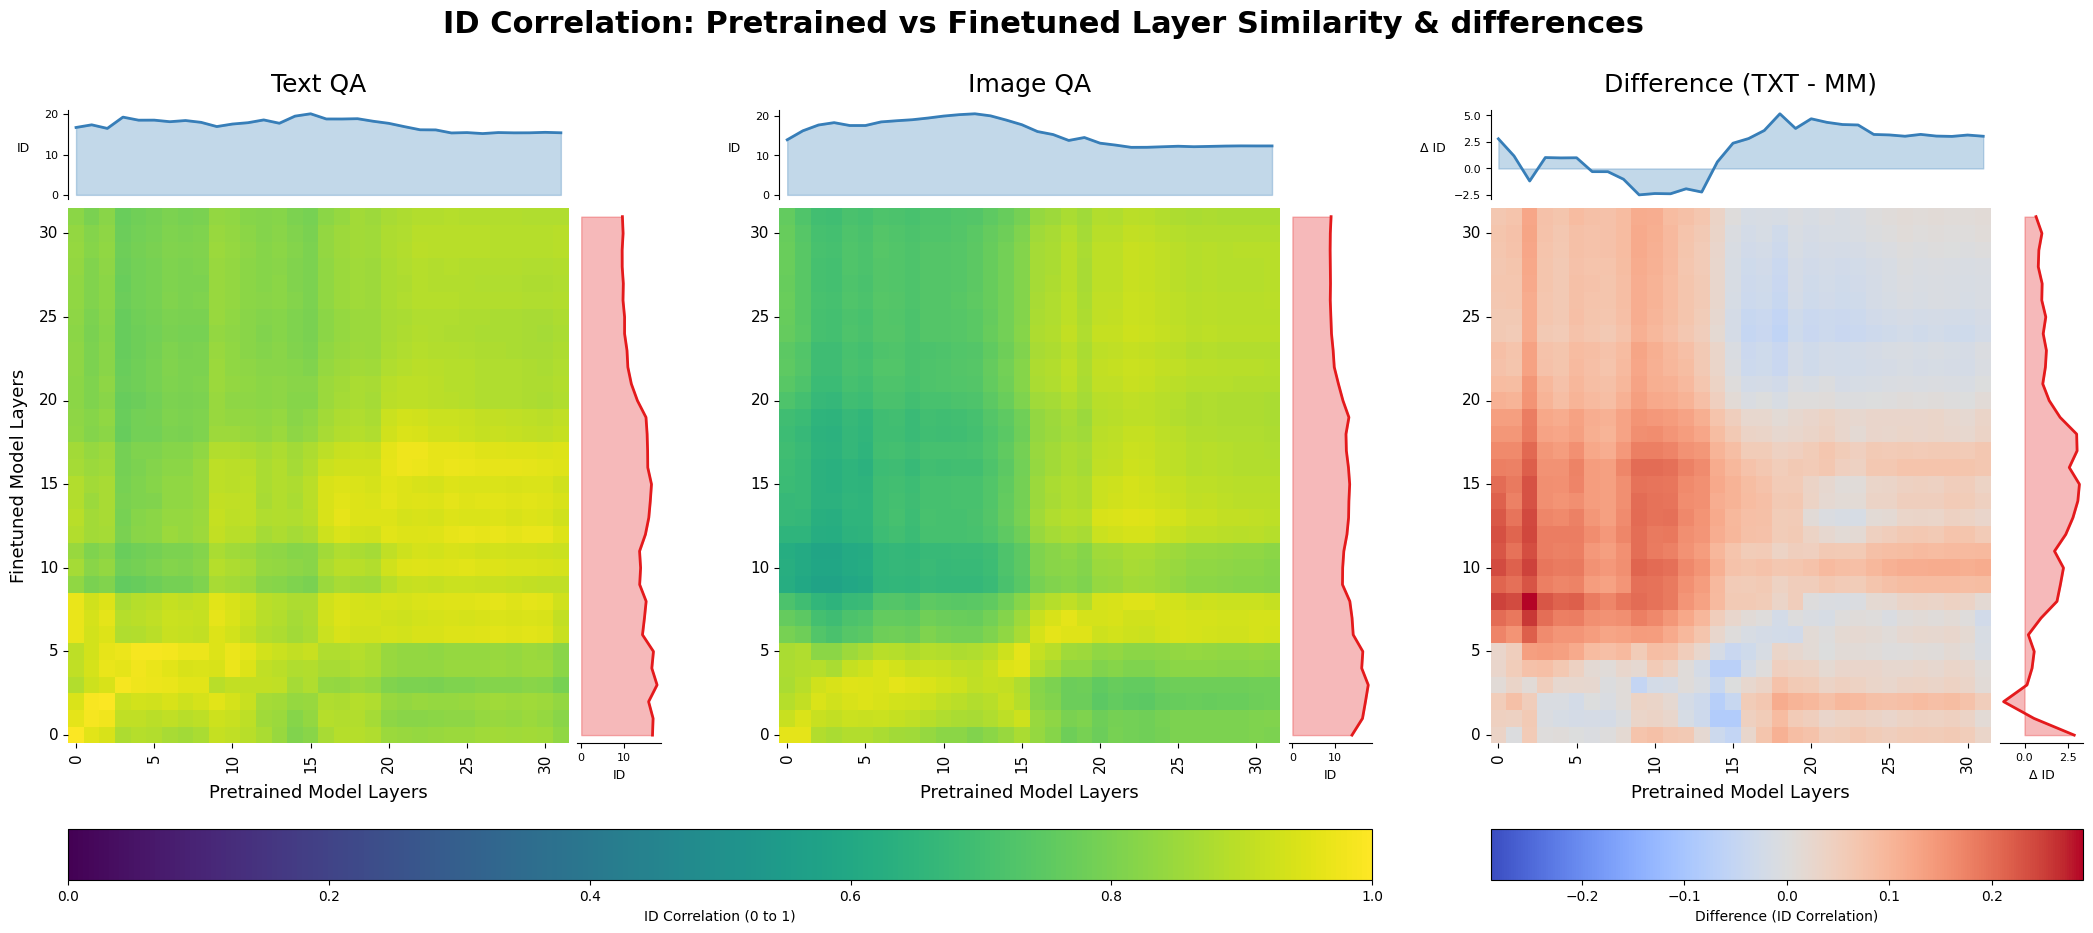

Saved plot to ../plots/models_similarity/models_similarity_information_imbalance_with_id.png


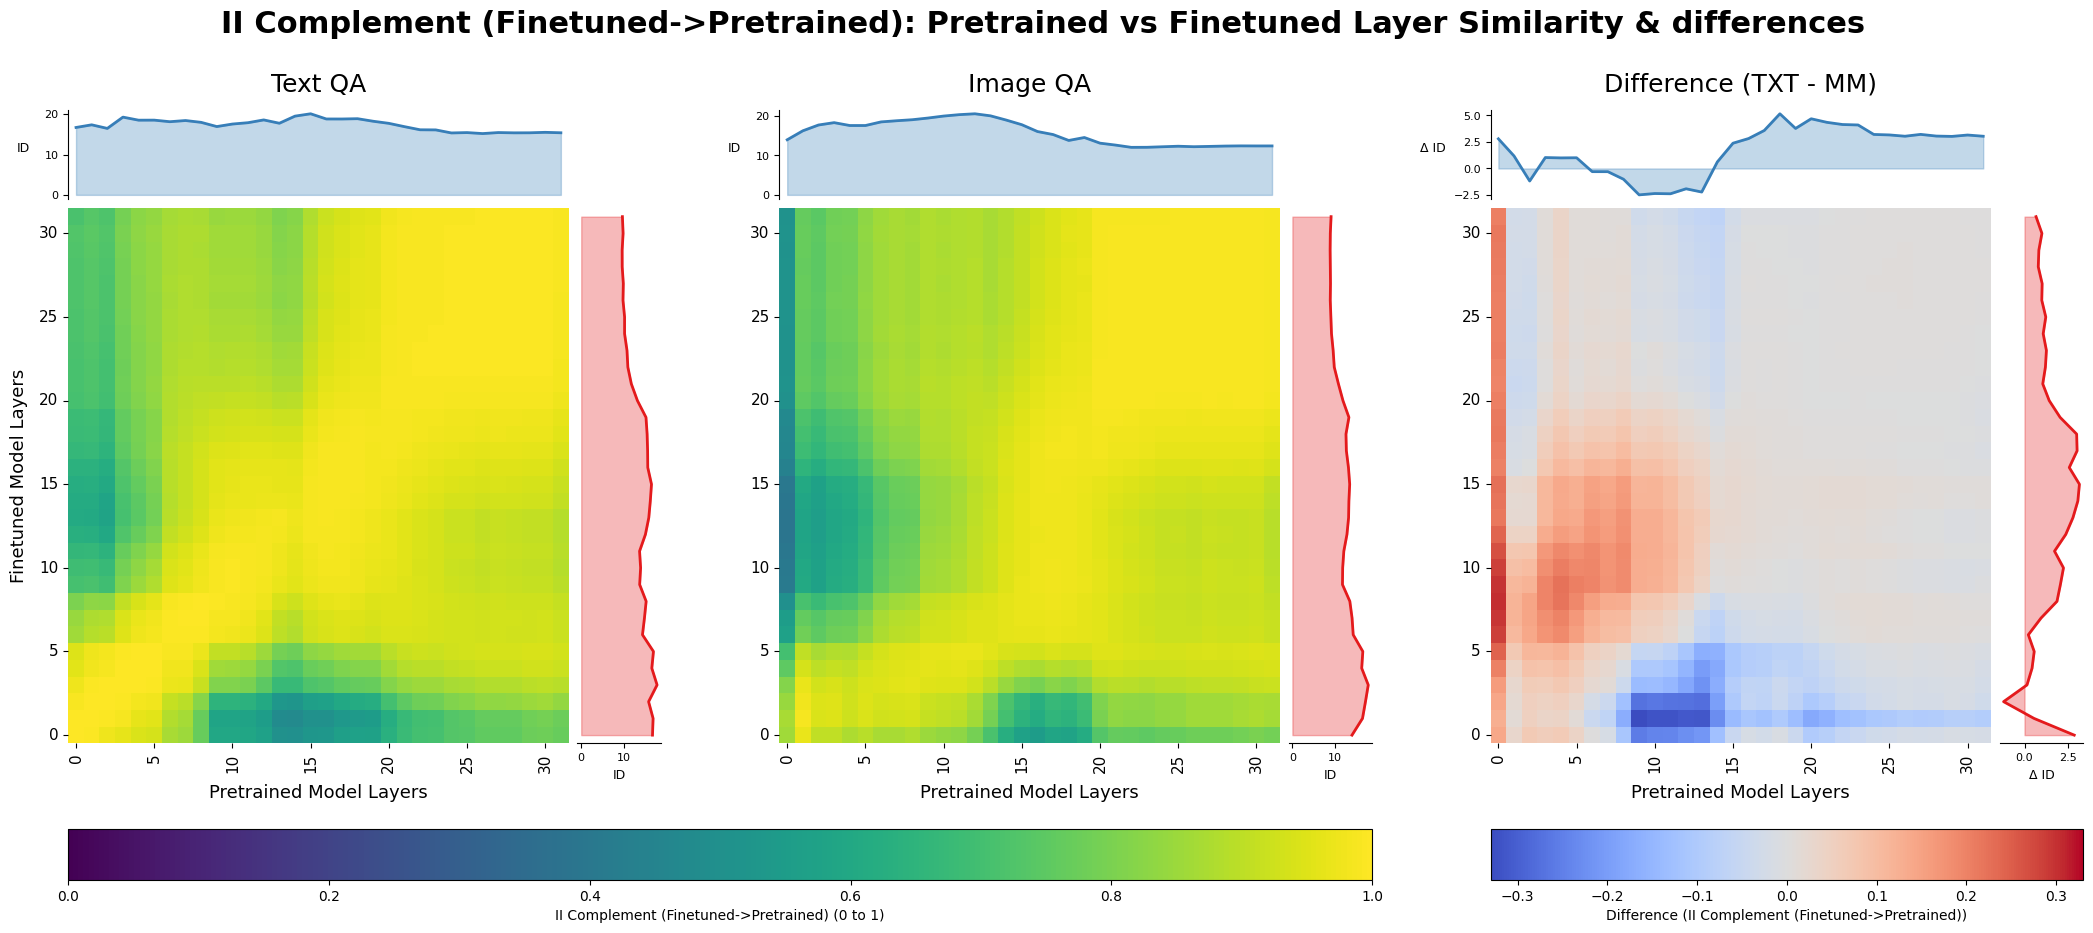

Saved plot to ../plots/models_similarity/models_similarity_information_imbalance_reversed_with_id.png


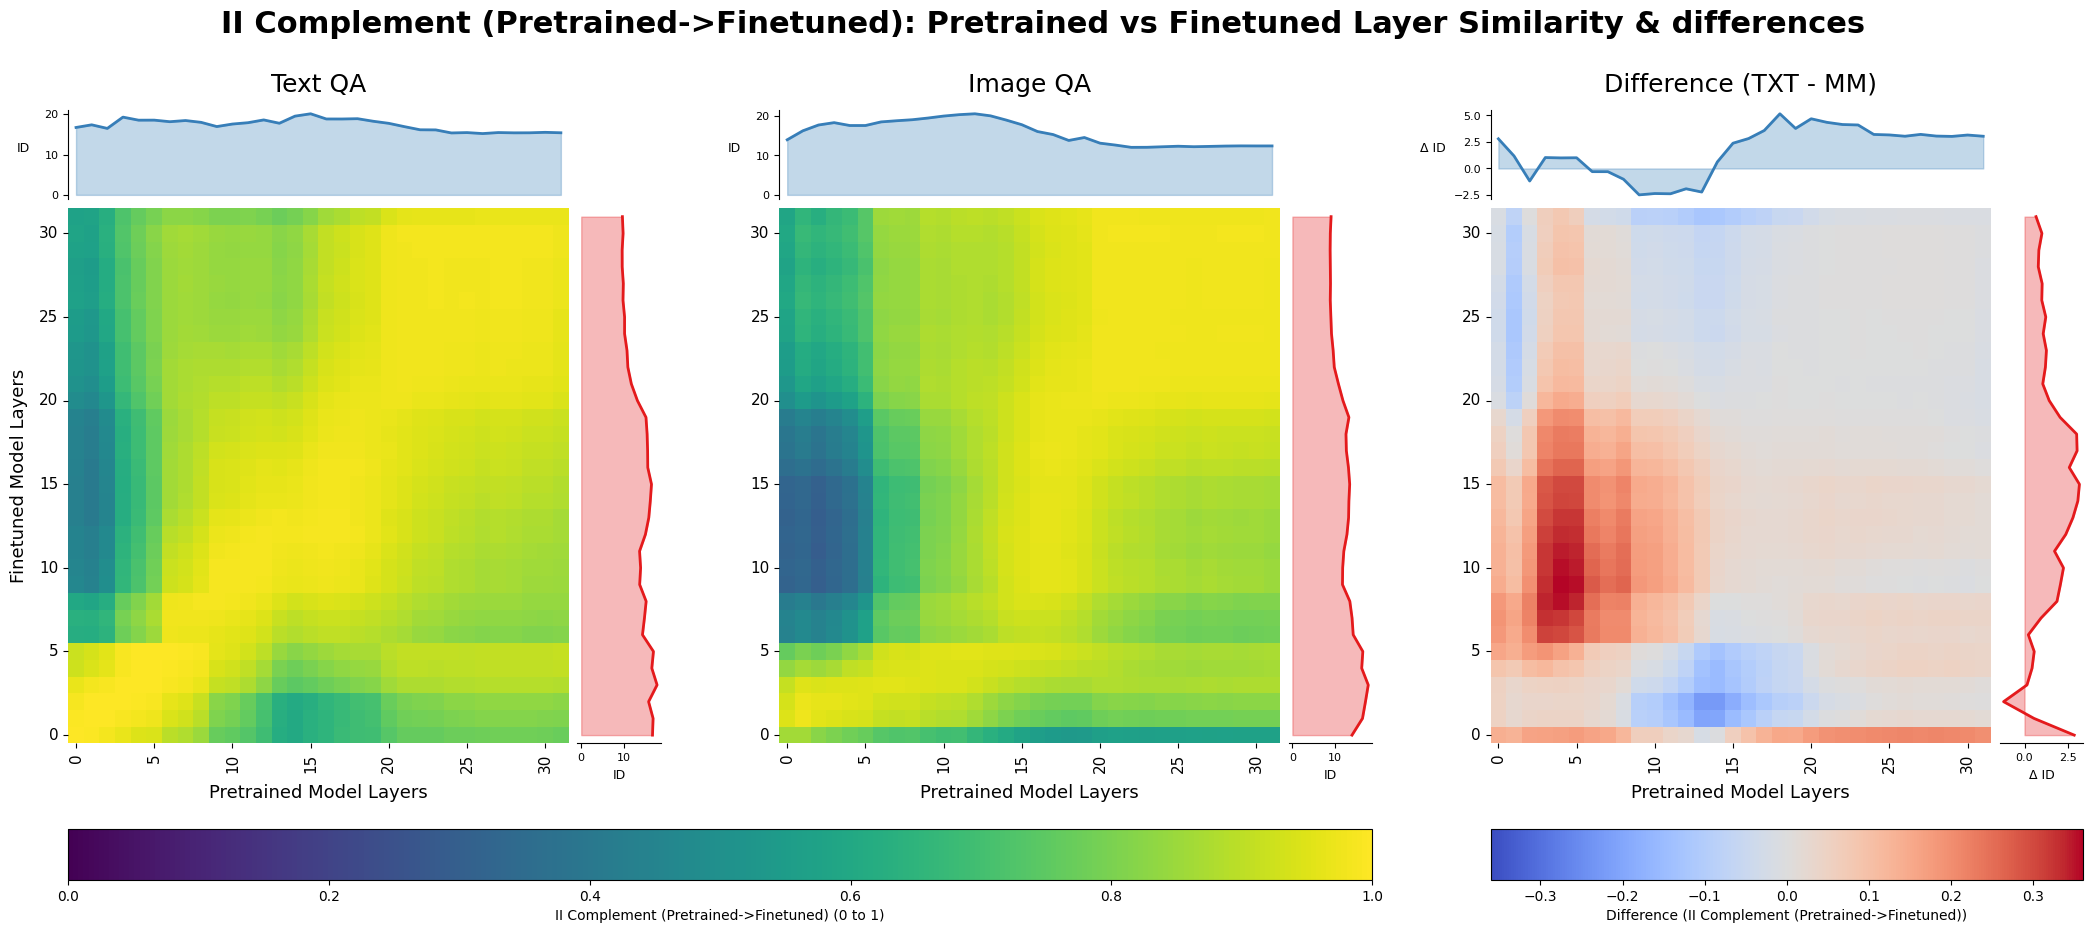

Saved plot to ../plots/models_similarity/models_similarity_information_imbalance_mean_with_id.png


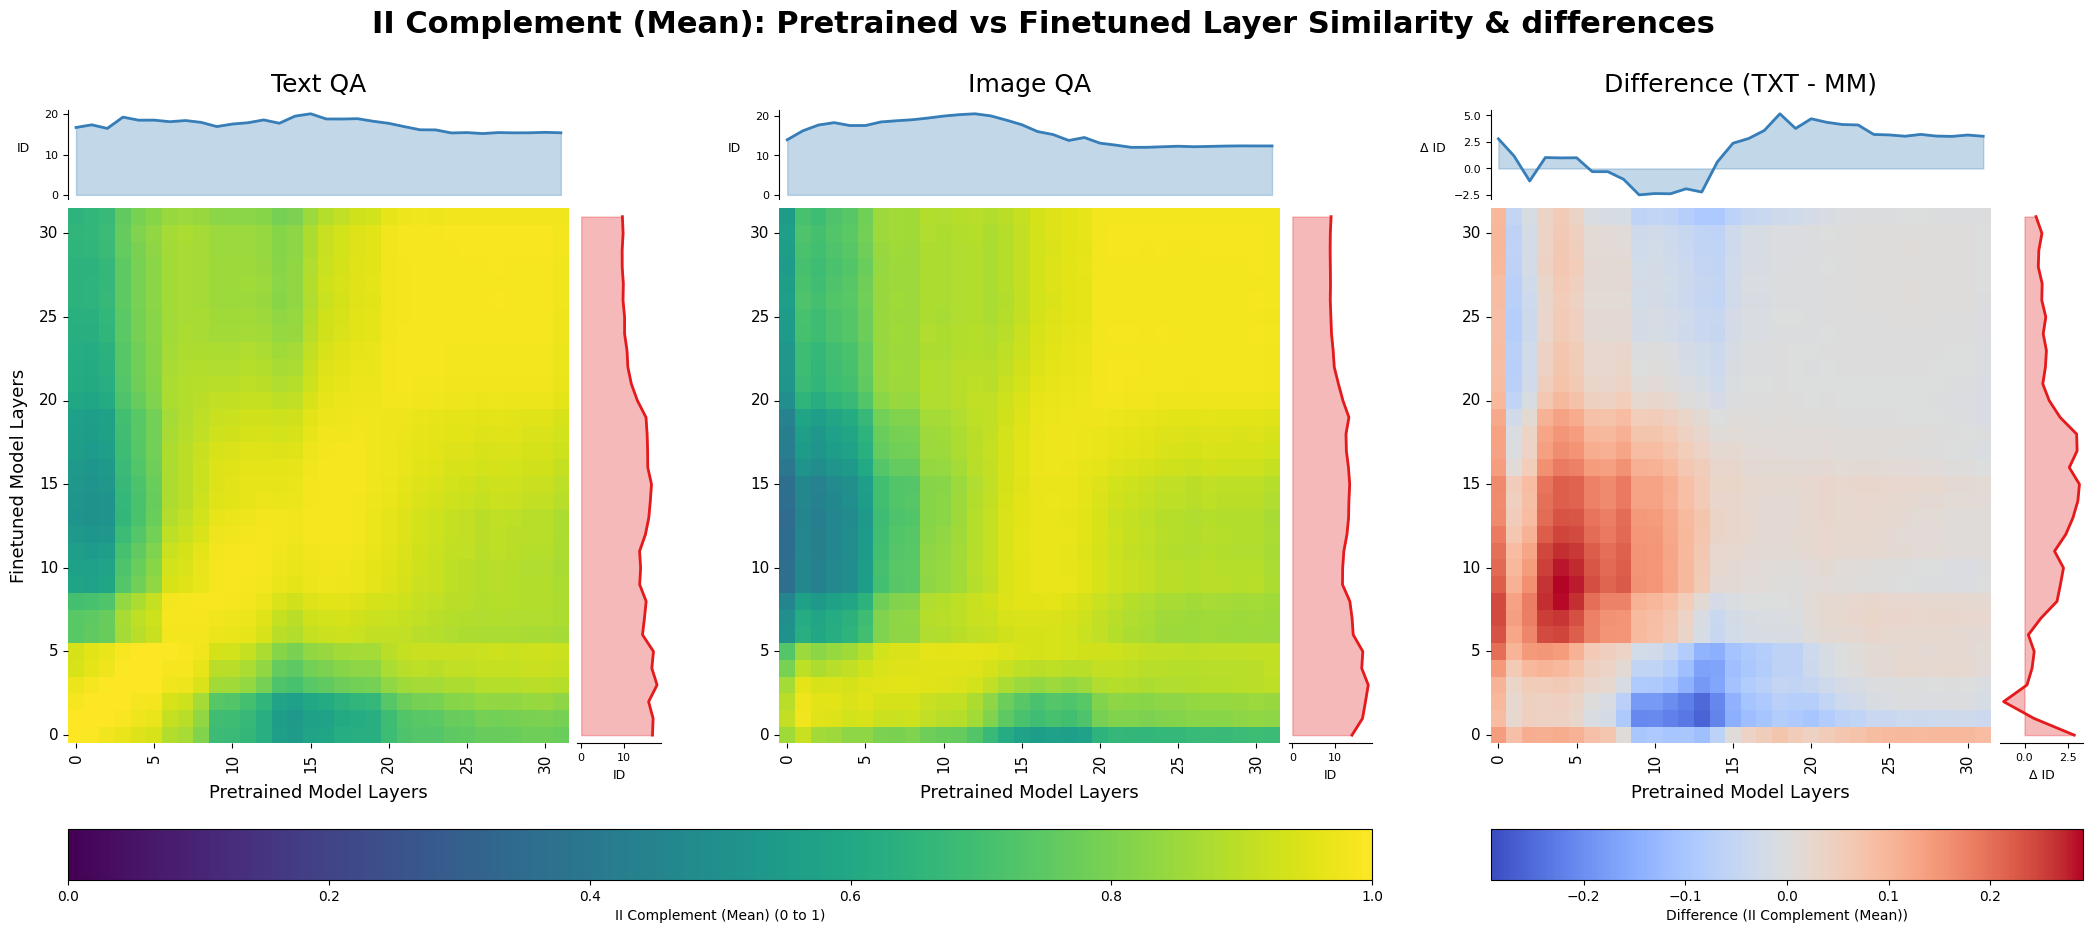

In [6]:
# Generate plots for all measures
for key, title in MEASURES.items():
    plot_model_comparison(key, title)